# SANPO-Real HEAD (5 FPS) — exploration and representative validation split

This notebook **adapts the method from the team's original Chest `validation_split.ipynb`**, not its chosen sessions.
It works on the **local** `sanpo_real_head_5fps` data already downloaded on Windows (no Modal and no training).

**What it does:**
1. Check official Head train/test sessions and their overlap with Chest validation and test sessions.
2. Profile **all** Head frames: original 31-class pixel counts, sharpness, and **official** human/machine annotation types. Cache one CSV per session to resume if interrupted.
3. Explore original classes, sharpness and example masks (including any Head-only bus-stop pixels).
4. Read official walk descriptions; propose a validation split of **whole Head sessions** (about 10% of official Head train) using the same class, weather, environment, crowd and annotation criteria as the Chest notebook.
5. Present tables and figures. **Does not publish `validation_walks.txt` unless you explicitly change `SAVE_SPLIT = True` after reviewing it.**

**Safety:** No changes to Chest data, Chest validation, official SANPO test, teammate source scripts, training weights, or Git. Generated caches/reports are under **this notebook's own `results/` folder**. If class distribution means the original strict Chest rules are infeasible, the search stops and requests review, rather than weakening rules silently.

**Source:** adapted from your teammate's `validation_split.ipynb`. For Head, the population and metadata must be measured again.


## 1. Settings

In [1]:
from pathlib import Path

# Open this notebook in VSCode. Update REPO only if you moved your project.
REPO = Path(r"C:\Projects\blind-guide")
HEAD_DATA = REPO / "fast_path/object_detection/data/sanpo/sanpo_real_head_5fps"
CHEST_DATA = REPO / "fast_path/object_detection/data/sanpo/sanpo_real_chest_5fps"
SANPO_CODE = REPO / "fast_path/object_detection/data_code/sanpo"
WORK_DIR = SANPO_CODE / "head_validation_split"
RESULTS_DIR = WORK_DIR / "results"
PROFILE_DIR = RESULTS_DIR / "profiles"
CLASS_PIXELS_FILE = RESULTS_DIR / "class_pixels_per_frame.csv"
SHARPNESS_FILE = RESULTS_DIR / "sharpness_scores.csv"
LABEL_SOURCE_FILE = RESULTS_DIR / "label_source_per_frame.csv"
DESCRIPTIONS_DIR = RESULTS_DIR / "descriptions"
DATASET_DIR = HEAD_DATA

# Adapted from the friend's Chest rules; inspect Head distributions before accepting.
VALIDATION_WALKS = None  # auto: 10% of *eligible* Head train walks, set in section 5
FRAME_SHARE_RANGE = (0.08, 0.12)
REQUIRED_CLASS_MIN_WALKS = 30
MIN_FRAMES_IN_VALIDATION = 10
MIN_RELATIVE_FRAME_SHARE = 0.25
MAX_RELATIVE_FRAME_SHARE = 4.0
MAX_SHARE_OF_CLASS_WALKS = 1 / 3
HEAVY_TRAFFIC_WALKS = None  # from the Head training data (not Chest's fixed 2)
IGNORED_CLASSES = ["unlabeled", "bus stop"]  # same 29-class task as Chest; review bus-stop counts below
BLURRY_PERCENTILE = 5

CANDIDATES = 400000  # Chest used 2 million; increase only if Head's strict rules are feasible
SWAP_STARTS = 10
NORMALIZATION_CANDIDATES = 20000
SEED = 42
final_walks = [
    "8bWymqLVx34nEZhZek77q8WqIEvRucxE",
    "FeJgoz6tfxhlDqiesDGIZdbM3VoE_HMZ",
    "R0zL2no8ujqRzo45_vBv-ca8HSh_6vxo",
    "TccwLbeRW-z_NPDDJsr1S3IC-iUzaJI3",
    "hkerfVO2smIEaljAGTK7hi_FxLt4mAmH",
    "j5QOrc58fUSYWM7vbUAn0g4NIRwfOhBg",
    "n3XL5R4agzVZ7DKs-j8dfEBkmqznu_Ck",
]
FIXED_VALIDATION_WALKS = final_walks
SAVE_SPLIT = True  # final fixed split; publishing cell will not overwrite existing saved files

for p in [HEAD_DATA, CHEST_DATA, HEAD_DATA / "index", HEAD_DATA / "sanpo_meta/labelmap.json"]:
    print(('FOUND  ' if p.exists() else 'MISSING'), p)
assert HEAD_DATA.is_dir() and (HEAD_DATA / 'index').is_dir(), 'Head download missing'


FOUND   C:\Projects\blind-guide\fast_path\object_detection\data\sanpo\sanpo_real_head_5fps
FOUND   C:\Projects\blind-guide\fast_path\object_detection\data\sanpo\sanpo_real_chest_5fps
FOUND   C:\Projects\blind-guide\fast_path\object_detection\data\sanpo\sanpo_real_head_5fps\index
FOUND   C:\Projects\blind-guide\fast_path\object_detection\data\sanpo\sanpo_real_head_5fps\sanpo_meta\labelmap.json


## 2. Imports

In [2]:
import csv
import json
import os
import time
import urllib.parse
import urllib.request
from collections import Counter
from concurrent.futures import ThreadPoolExecutor

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

cv2.setNumThreads(1)
pd.set_option('display.max_rows', 100)
pd.set_option('display.width', 220)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
PROFILE_DIR.mkdir(parents=True, exist_ok=True)


## 2A. Official split inventory and cross-camera protection

Read index CSVs rather than guessing session IDs from filenames. Head's official **test** is never used to choose validation walks. Check Head train against **both** Chest validation and Chest official test, not just Chest validation. The camera data may belong to disjoint annotated sessions; let the IDs prove it.

In [3]:
def index_records(root, expected_camera):
    parts = []
    for path in sorted((root / "index").glob("*.csv")):
        part = pd.read_csv(path, dtype={"frame_id": "str"})
        if part.empty:
            raise ValueError(f"Empty index: {path}")
        if set(part["camera"]) != {expected_camera}:
            raise ValueError(f"Wrong camera in {path}")
        if set(part["session"]) != {path.stem} or len(set(part["split"])) != 1:
            raise ValueError(f"Inconsistent session/split in {path}")
        if not set(part["split"]) <= {"train", "test"}:
            raise ValueError(f"Unexpected official split in {path}")
        parts.append(part)
    if not parts:
        raise FileNotFoundError(f"No indexes found in {root / 'index'}")
    df = pd.concat(parts, ignore_index=True)
    if df["frame"].duplicated().any() or df["mask"].duplicated().any():
        raise ValueError("Duplicate image or mask references in index")
    return df

head_index = index_records(HEAD_DATA, 'head')
chest_index = index_records(CHEST_DATA, 'chest')
head_official_train = set(head_index.loc[head_index.split == 'train', 'session'])
head_official_test = set(head_index.loc[head_index.split == 'test', 'session'])
chest_official_train = set(chest_index.loc[chest_index.split == 'train', 'session'])
chest_official_test = set(chest_index.loc[chest_index.split == 'test', 'session'])
chest_val_path = SANPO_CODE / 'validation_split/results/validation_walks.txt'
chest_val = set(chest_val_path.read_text(encoding='utf-8').split())
assert chest_val <= chest_official_train, 'Chest val IDs do not match the Chest official train index'
assert not (head_official_train & head_official_test), 'Head train/test overlap!'
collisions = {
    'Head train vs Chest val': sorted(head_official_train & chest_val),
    'Head train vs Chest test': sorted(head_official_train & chest_official_test),
    'Head test vs Chest train': sorted(head_official_test & chest_official_train),
    'Head train vs Chest train': sorted(head_official_train & chest_official_train),
}
print('Head official:', head_index.groupby('split').agg(frames=('frame','size'), sessions=('session','nunique')).to_string())
for name, ids in collisions.items():
    print(name, 'overlaps:', len(ids), '(examples:', ids[:3], ')')
# Do NOT train on Head sessions belonging to any Chest validation/test session.
head_eligible_train = head_official_train - set(collisions['Head train vs Chest val']) - set(collisions['Head train vs Chest test'])
print('Head eligible train sessions after protecting Chest validation/test:', len(head_eligible_train))
if collisions['Head test vs Chest train']:
    print('CAUTION: Chest training overlaps Head official test; do not report post-Chest Head-test scores as independent.')
if not head_eligible_train:
    raise RuntimeError('No Head training walks remain after leakage protection')

Head official:        frames  sessions
split                  
test     2603        18
train   11218        73
Head train vs Chest val overlaps: 0 (examples: [] )
Head train vs Chest test overlaps: 0 (examples: [] )
Head test vs Chest train overlaps: 0 (examples: [] )
Head train vs Chest train overlaps: 0 (examples: [] )
Head eligible train sessions after protecting Chest validation/test: 73


## 2B. Build Head statistics (resumable, CPU only)

Reads the **original PNG mask's red channel** (SANPO class ID), counts pixels of every original class, measures image sharpness using the **same Laplacian-variance method** as your teammate's blur analysis, and reads the official HUMAN/MACHINE annotation type JSON. Each session is cached separately: an interrupted run can resume without re-reading finished walks. Small official JSON metadata may be fetched from Google's public SANPO bucket; **no video/image redownload**.

In [4]:
ROOT_URL = 'https://storage.googleapis.com/gresearch/sanpo_dataset/v0/sanpo-real'
labelmap = json.loads((HEAD_DATA / 'sanpo_meta/labelmap.json').read_text(encoding='utf-8'))
class_names_by_id = [name for name, value in sorted(labelmap.items(), key=lambda pair: int(pair[1]))]
if sorted(map(int,labelmap.values())) != list(range(len(labelmap))):
    raise ValueError('Expected contiguous raw SANPO class IDs')
num_classes = len(labelmap)
print('Original SANPO classes:', num_classes, '| supervised Chest classes:', num_classes - len(IGNORED_CLASSES))
if not set(IGNORED_CLASSES) <= set(labelmap):
    raise ValueError('Required ignored category absent from Head labelmap')

def small_official_json(session, suffix, cache_dir):
    cache_dir.mkdir(parents=True, exist_ok=True)
    cache = cache_dir / f'{session}.json'
    if not cache.exists():
        url = f'{ROOT_URL}/{urllib.parse.quote(session)}/{suffix}'
        for attempt in range(5):
            try:
                with urllib.request.urlopen(url, timeout=60) as response:
                    body = response.read()
                json.loads(body)  # validate before caching
                temp = cache.with_suffix('.tmp')
                temp.write_bytes(body)
                temp.replace(cache)
                break
            except Exception:
                if attempt == 4:
                    raise
                time.sleep(min(2**attempt, 8))
    return json.loads(cache.read_text(encoding='utf-8'))

def frame_statistics(image_path, mask_path):
    mask = cv2.imread(str(mask_path), cv2.IMREAD_COLOR)
    if mask is None:
        raise ValueError(f'Unreadable mask: {mask_path}')
    raw_class = mask[:, :, 2]  # OpenCV BGR: red = class id
    bins = np.bincount(raw_class.ravel(), minlength=256)
    unknown = int(bins[num_classes:].sum())
    if unknown:
        raise ValueError(f'{unknown} pixels contain unexpected class IDs in {mask_path}')
    gray = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)
    if gray is None:
        raise ValueError(f'Unreadable image: {image_path}')
    height, width = gray.shape
    gray = cv2.resize(gray, (640, max(1, round(height * 640 / width))), interpolation=cv2.INTER_AREA)
    score = float(cv2.Laplacian(gray, cv2.CV_64F).var())
    return bins[:num_classes], score

def profile_one_session(session, table):
    cache = PROFILE_DIR / f'{session}.csv'
    if cache.exists():
        df = pd.read_csv(cache)
        if (len(df) == len(table) and set(df['frame_id'].astype(int)) == set(table['frame_id'].astype(int))
                and all(name in df for name in class_names_by_id) and 'label_source' in df and 'score' in df):
            return df
    ann = small_official_json(session, 'camera_head/left/frame_segmentation_annotation_type.json',
                              RESULTS_DIR / 'annotation_types')
    records = []
    for row in table.itertuples(index=False):
        img = HEAD_DATA / row.frame
        mask = HEAD_DATA / row.mask
        if not img.is_file() or not mask.is_file():
            raise FileNotFoundError(f'Missing indexed image or mask for {session}: {img} / {mask}')
        counts, sharpness_score = frame_statistics(img, mask)
        status = ann.get(str(int(row.frame_id)))
        if status not in ('HUMAN_ANNOTATED','MACHINE_ANNOTATED'):
            raise ValueError(f'Unknown annotation source {status!r} for {session} frame {row.frame_id}')
        record = dict(split=row.split, session=session, frame_id=int(row.frame_id),
                      image=Path(row.frame).name, mask=row.mask,
                      label_source='human' if status == 'HUMAN_ANNOTATED' else 'machine',
                      score=sharpness_score)
        record.update({name:int(counts[i]) for i,name in enumerate(class_names_by_id)})
        records.append(record)
    df = pd.DataFrame(records)
    tmp = cache.with_suffix('.partial.csv')
    df.to_csv(tmp, index=False)
    tmp.replace(cache)
    return df

start = time.time()
chunks=[]
for i,(session,group) in enumerate(head_index.groupby('session', sort=True), start=1):
    chunks.append(profile_one_session(session,group))
    if i%10==0 or i==head_index.session.nunique():
        print(f'Profiled {i}/{head_index.session.nunique()} Head walks in {time.time()-start:.0f}s',flush=True)
all_profiles = pd.concat(chunks, ignore_index=True)
assert len(all_profiles) == len(head_index)
all_profiles[['mask']+class_names_by_id].to_csv(CLASS_PIXELS_FILE, index=False)
all_profiles[['image','score']].to_csv(SHARPNESS_FILE, index=False)
all_profiles[['image','label_source']].to_csv(LABEL_SOURCE_FILE, index=False)
print('Head full-profile complete:',len(all_profiles),'frames')
print('Official split counts:',all_profiles['split'].value_counts().to_dict())
print('Human/machine:',all_profiles['label_source'].value_counts().to_dict())
print('Bus stop pixels (Head):',int(all_profiles.get('bus stop',pd.Series([0])).sum()))
if all_profiles.get('bus stop',pd.Series([0])).sum()>0:
    print('CAUTION: Head contains bus-stop pixels. Using the Chest 29-class mapping would IGNORE them; discuss before training.')

Original SANPO classes: 31 | supervised Chest classes: 29
Profiled 10/91 Head walks in 0s
Profiled 20/91 Head walks in 0s
Profiled 30/91 Head walks in 0s
Profiled 40/91 Head walks in 0s
Profiled 50/91 Head walks in 0s
Profiled 60/91 Head walks in 0s
Profiled 70/91 Head walks in 0s
Profiled 80/91 Head walks in 0s
Profiled 90/91 Head walks in 0s
Profiled 91/91 Head walks in 0s
Head full-profile complete: 13821 frames
Official split counts: {'train': 11218, 'test': 2603}
Human/machine: {'machine': 6998, 'human': 6823}
Bus stop pixels (Head): 2923365
CAUTION: Head contains bus-stop pixels. Using the Chest 29-class mapping would IGNORE them; discuss before training.


## 2C. Explore Head classes and example images

Inspect which classes are rare and whether labels visually match the image. These are not model scores.

Class frequency (official Head train and test; original taxonomy):


,split,class,pixel share %,frames,frame share %
60,test,vegetation,22.5899,2414,92.74
37,test,paved trail,15.3893,1435,55.13
58,test,sky,14.9357,2215,85.09
39,test,wall/fence,8.7937,2046,78.60
59,test,tree,8.7897,1788,68.69
61,test,terrain,7.3145,1876,72.07
38,test,building,5.7225,1320,50.71
34,test,sidewalk,5.2885,825,31.69
43,test,pedestrian,3.1885,1604,61.62
32,test,road,1.7399,580,22.28


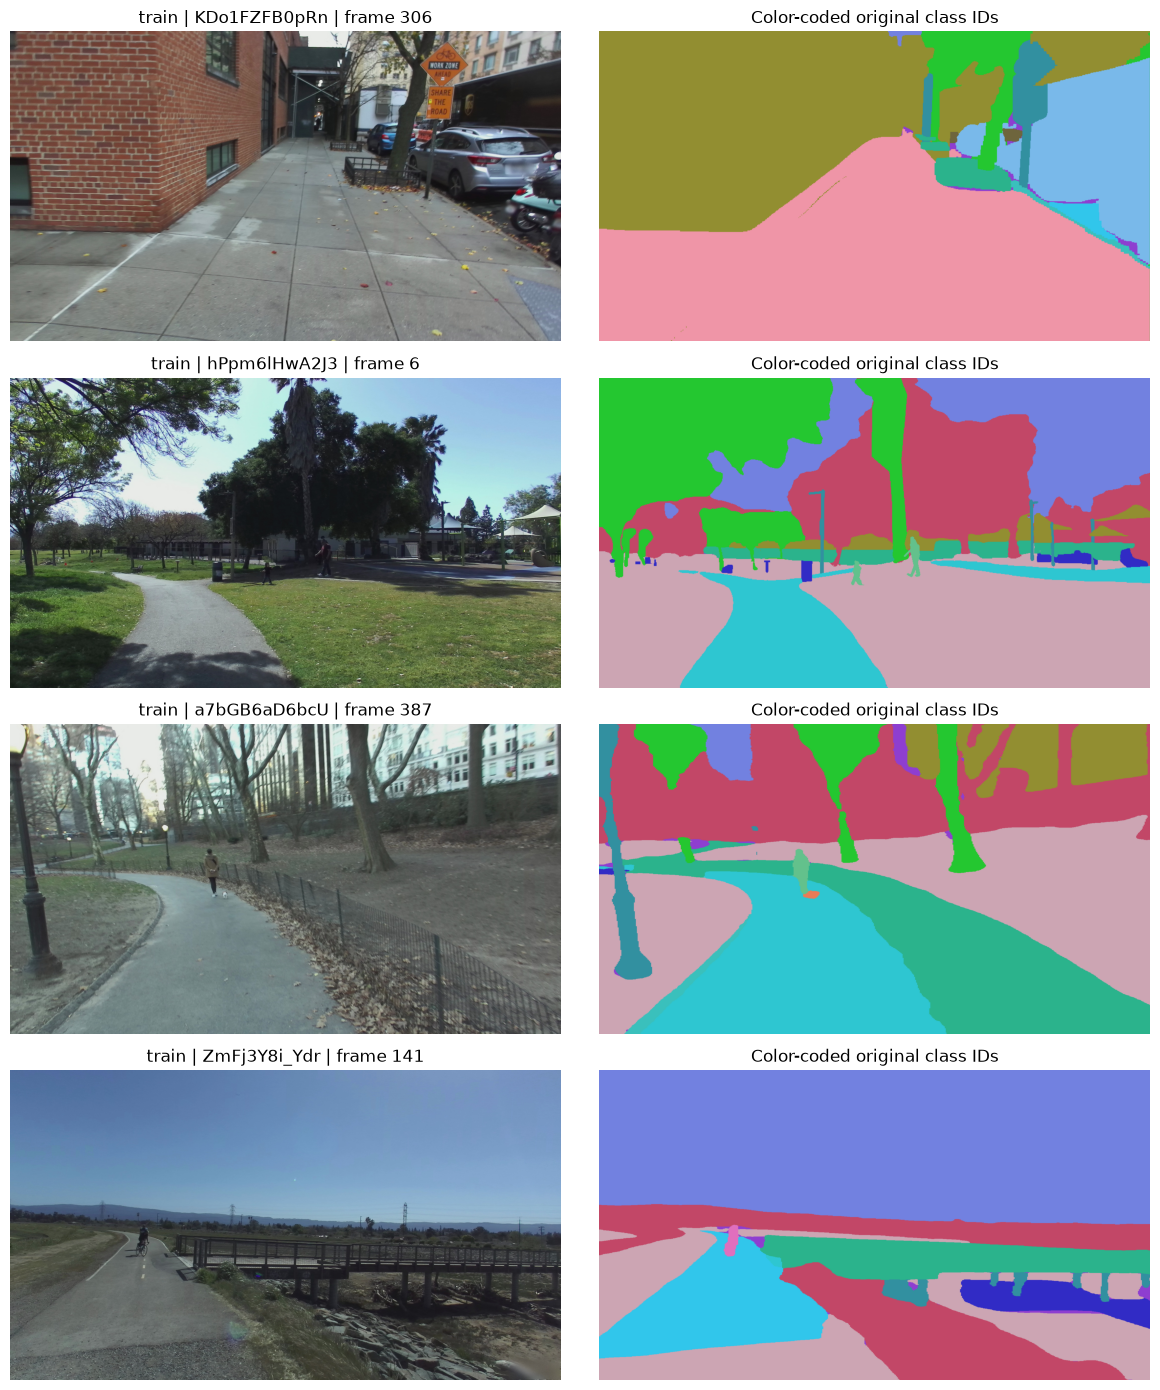

In [5]:
profile_table = []
for split in ('train', 'test'):
    rows = all_profiles.loc[all_profiles.split == split, class_names_by_id]
    pixel_sums = rows.sum()
    for name in class_names_by_id:
        profile_table.append({'split':split, 'class':name,
                              'pixel share %': round(float(100*pixel_sums[name] / pixel_sums.sum()),4),
                              'frames':int((rows[name]>0).sum()),
                              'frame share %':round(float(100*(rows[name]>0).mean()),2)})
print('Class frequency (official Head train and test; original taxonomy):')
display(pd.DataFrame(profile_table).sort_values(['split','pixel share %'],ascending=[True,False]))
rng = np.random.default_rng(42)
sampled = all_profiles.sample(n=min(4,len(all_profiles)),random_state=42)
color_table = rng.integers(32,240,(256,3),dtype=np.uint8)
fig,ax=plt.subplots(len(sampled),2,figsize=(12,3.5*len(sampled)),squeeze=False)
for (idx,row), (a,b) in zip(sampled.iterrows(),ax):
    raw = cv2.imread(str(HEAD_DATA/'frames'/row['split']/row['image']))
    raw = cv2.cvtColor(raw,cv2.COLOR_BGR2RGB)
    original_mask = cv2.imread(str(HEAD_DATA/row['mask']),cv2.IMREAD_COLOR)[:,:,2]
    a.imshow(raw); a.set_title(f"{row['split']} | {row['session'][:12]} | frame {row['frame_id']}")
    b.imshow(color_table[original_mask]); b.set_title('Color-coded original class IDs')
    a.axis('off'); b.axis('off')
plt.tight_layout(); plt.show()

## 3. Official Head training frames only

Class pixels, blur score and provenance were computed in Section 2B for all Head frames. Here we use **only official train** (never test) for the validation selection.


In [6]:
# Class pixels per frame: one column per SANPO class
frames = pd.read_csv(CLASS_PIXELS_FILE)
frames["folder"] = frames["mask"].str.split("/").str[1]  # train / val / test folder of our copy
frames = frames[(frames["folder"] == "train")].reset_index(drop=True)  # official train split only
frames = frames[frames["mask"].str.rsplit("/",n=1).str[-1].str.rsplit("_",n=1).str[0].isin(head_eligible_train)].reset_index(drop=True)  # cross-camera protection
frames["image"] = frames["mask"].str.rsplit("/", n=1).str[-1].str.replace(".png", ".jpg")
frames["session"] = frames["image"].str.rsplit("_", n=1).str[0]  # walk id = file name without the frame number

all_class_names = [column for column in frames.columns if column not in ("mask", "folder", "image", "session")]
class_names = []
for class_name in all_class_names:
    if class_name not in IGNORED_CLASSES:
        class_names.append(class_name)

# Sharpness score per frame; "blurry" = lowest BLURRY_PERCENTILE % of ALL frames (train and test)
sharpness = pd.read_csv(SHARPNESS_FILE)
blurry_score = np.percentile(sharpness["score"], BLURRY_PERCENTILE)
frames = frames.merge(sharpness[["image", "score"]], on="image", how="left")
frames["blurry"] = frames["score"] < blurry_score

# Label source per frame: human-made or machine-made
label_source = pd.read_csv(LABEL_SOURCE_FILE)
frames = frames.merge(label_source[["image", "label_source"]], on="image", how="left")
frames["human_labeled"] = frames["label_source"] == "human"

assert frames["score"].notna().all(), "some frames have no sharpness score"
assert frames["label_source"].notna().all(), "some frames have no label source"
print(f"{len(frames):,} frames in {frames['session'].nunique()} walks | {len(class_names)} classes used "
      f"(left out: {', '.join(IGNORED_CLASSES)}) | blurry = sharpness score below {blurry_score:.0f}")

11,218 frames in 73 walks | 29 classes used (left out: unlabeled, bus stop) | blurry = sharpness score below 203


## 4. SANPO official attributes per Head walk

Use `description.json` metadata for each **eligible Head training walk**. Cache under this notebook’s own results folder.


In [7]:
SANPO_URL = "https://storage.googleapis.com/gresearch/sanpo_dataset/v0/sanpo-real"
DESCRIPTIONS_DIR.mkdir(parents=True, exist_ok=True)


def read_description(session):
    """SANPO's description of one walk: downloaded the first time, then read from DESCRIPTIONS_DIR.

    Returns the walk's attributes (the "session_video_metadata" part of description.json).
    """
    path = DESCRIPTIONS_DIR / f"{session}.json"
    if not path.exists():
        url = f"{SANPO_URL}/{urllib.parse.quote(session)}/description.json"
        for attempt in range(5):
            try:
                with urllib.request.urlopen(url, timeout=60) as response:
                    data = response.read()
                break
            except Exception:
                if attempt == 4:
                    raise
                time.sleep(2 ** attempt)
        path.write_bytes(data)
    return json.loads(path.read_text())["session_video_metadata"]


sessions = sorted(frames["session"].unique())  # fixed order: the selection depends on it
start_time = time.time()
with ThreadPoolExecutor(16) as pool:
    # read_description takes: a walk id; returns: its attributes (dictionary)
    descriptions = dict(zip(sessions, pool.map(read_description, sessions)))
print(f"descriptions of {len(descriptions)} walks ready in {time.time() - start_time:.1f}s")


def short(value):
    """ENVIRONMENT_TYPE_PARK -> park"""
    for prefix in ["ENVIRONMENT_TYPE_", "WEATHER_CONDITION_", "MOTION_BLUR_", "HUMAN_TRAFFIC_", "VISIBILITY_"]:
        value = value.replace(prefix, "")
    return value.lower().replace("_", " ")


walk_attributes = pd.DataFrame({
    "environment types": [[short(value) for value in descriptions[session].get("environment_types", [])] for session in sessions],
    "weather": [[short(value) for value in descriptions[session].get("weather_conditions", [])] for session in sessions],
    "motion blur (SANPO)": [short(descriptions[session].get("motion_blur", "unknown")) for session in sessions],
    "human traffic": [short(descriptions[session].get("human_traffic", "unknown")) for session in sessions],
}, index=sessions)
walk_attributes.head()

descriptions of 73 walks ready in 0.0s


,environment types,weather,motion blur (SANPO),human traffic
-koZLfrjI5P5NIBgB4f_4jpMSMxsd9pH,[park],[sunny],medium,low
1H3E6EdKXElNb9dwktawcA-tEBYUbu7J,[park],[sunny],low,low
28tdwxgz-zPU06lpeDY3OPWTFxZyBv2c,"[urban, park, open space]",[sunny],low,moderate
2N3D8fo4jJ7GsPFuC89q0QeXO1dEteWS,[rural],[sunny],low,low
5ds11qbJuU0H6GEVLo67pCSNmTbpTsrL,[rural],[sunny],low,low


## 5. One row per walk

Everything the rules and the scores need, summed per walk.

In [8]:
per_walk = frames.groupby("session")
walk_frames = per_walk.size().reindex(sessions).to_numpy()
walk_human_frames = per_walk["human_labeled"].sum().reindex(sessions).to_numpy()
walk_blurry_frames = per_walk["blurry"].sum().reindex(sessions).to_numpy()
walk_class_pixels = per_walk[class_names].sum().reindex(sessions).to_numpy(dtype=np.float64)  # walks x classes
walk_class_frames = (frames[class_names] > 0).groupby(frames["session"]).sum().reindex(sessions).to_numpy()  # frames containing the class

# Environment types as yes/no columns (a walk can have several)
environment_names = sorted({name for names in walk_attributes["environment types"] for name in names})
walk_environments = np.zeros((len(sessions), len(environment_names)))
for row, names in enumerate(walk_attributes["environment types"]):
    for name in names:
        walk_environments[row, environment_names.index(name)] = 1

# Weather conditions as yes/no columns (a walk can have several)
weather_names = sorted({name for names in walk_attributes["weather"] for name in names})
walk_weather = np.zeros((len(sessions), len(weather_names)))
for row, names in enumerate(walk_attributes["weather"]):
    for name in names:
        walk_weather[row, weather_names.index(name)] = 1

# Walks with heavy human traffic (crowds), from SANPO's walk descriptions
walk_heavy_traffic = (walk_attributes["human traffic"] == "heavy").to_numpy()
VALIDATION_WALKS = max(2,round(len(sessions) * 0.10)) if VALIDATION_WALKS is None else VALIDATION_WALKS
HEAVY_TRAFFIC_WALKS = int(round(VALIDATION_WALKS * walk_heavy_traffic.mean())) if HEAVY_TRAFFIC_WALKS is None else HEAVY_TRAFFIC_WALKS
print(f"Head selection target: {VALIDATION_WALKS} validation walks; heavy-traffic target: {HEAVY_TRAFFIC_WALKS}")
print(f"walks with heavy human traffic: {walk_heavy_traffic.sum()}")

# Classes that must appear in validation, and how many validation walks each class may take
class_walk_counts = (walk_class_pixels > 0).sum(axis=0)
required_classes = class_walk_counts >= REQUIRED_CLASS_MIN_WALKS
max_validation_walks_per_class = np.floor(class_walk_counts * MAX_SHARE_OF_CLASS_WALKS)

summary = pd.DataFrame({"train walks with the class": class_walk_counts,
                        "must appear in validation": required_classes,
                        "max validation walks": max_validation_walks_per_class.astype(int)}, index=class_names)
display(summary.sort_values("train walks with the class"))
print(f"{len(sessions)} walks | {walk_frames.sum():,} frames | environment types: {', '.join(environment_names)}")

Head selection target: 7 validation walks; heavy-traffic target: 1
walks with heavy human traffic: 13


,train walks with the class,must appear in validation,max validation walks
railway track,0,False,0
inaccessible surface,5,False,1
water body,6,False,2
opening-gate,7,False,2
hand rail,8,False,2
bike rack,10,False,3
stairs,12,False,4
guard rail/road barrier,18,False,6
traffic sign,18,False,6
opening-door,20,False,6


73 walks | 11,218 frames | environment types: open space, open terrain, park, road junction, rural, suburban, urban


## 6. Head validation selection — adapt the *method*, never the Chest walk IDs

Friend's original code compares train and validation using class pixel distributions, frame frequencies, weather, environment, label sources, blur and size. It first rejects candidates violating constraints and then improves valid candidates with walk swaps.

For Head: validation size is about 10% of **eligible Head train walks**; heavy-traffic count is estimated from Head, not copied from Chest. Strict rare-class rules are initially retained. If no candidates pass, inspect the printed feasibility information **before** deliberately changing a threshold. No automatic relaxation and no result published by this search cell.


In [9]:
def split_distances(is_validation):
    """Distances between validation (is_validation True) and train (False). Returns a dictionary of floats."""
    validation, train = is_validation, ~is_validation
    validation_frames, train_frames = walk_frames[validation].sum(), walk_frames[train].sum()
    validation_pixels = walk_class_pixels[validation].sum(axis=0)
    train_pixels = walk_class_pixels[train].sum(axis=0)
    return {
        "class pixels": 0.5 * np.abs(validation_pixels / validation_pixels.sum() - train_pixels / train_pixels.sum()).sum(),
        "class frames": np.abs(walk_class_frames[validation].sum(axis=0) / validation_frames
                               - walk_class_frames[train].sum(axis=0) / train_frames).mean(),
        "environments": np.abs(walk_environments[validation].mean(axis=0) - walk_environments[train].mean(axis=0)).mean(),
        "weather": np.abs(walk_weather[validation].mean(axis=0) - walk_weather[train].mean(axis=0)).mean(),
        "blurry": abs(walk_blurry_frames[validation].sum() / validation_frames - walk_blurry_frames[train].sum() / train_frames),
        "human-labeled": abs(walk_human_frames[validation].sum() / validation_frames - walk_human_frames[train].sum() / train_frames),
        "size": abs(validation_frames / walk_frames.sum() - 0.10),
    }


def broken_rules(is_validation):
    """The rules a candidate breaks (empty list = all rules kept)."""
    broken = []
    frame_share = walk_frames[is_validation].sum() / walk_frames.sum()
    if not FRAME_SHARE_RANGE[0] <= frame_share <= FRAME_SHARE_RANGE[1]:
        broken.append(f"validation holds {frame_share:.1%} of the frames")
    if walk_heavy_traffic[is_validation].sum() != HEAVY_TRAFFIC_WALKS:
        broken.append(f"{walk_heavy_traffic[is_validation].sum()} walks with heavy human traffic")
    validation_class_frames = walk_class_frames[is_validation].sum(axis=0)
    train_class_frames = walk_class_frames[~is_validation].sum(axis=0)
    validation_frame_count = walk_frames[is_validation].sum()
    train_frame_count = walk_frames[~is_validation].sum()
    validation_class_walks = (walk_class_pixels[is_validation] > 0).sum(axis=0)
    for index, class_name in enumerate(class_names):
        if required_classes[index] and validation_class_frames[index] < MIN_FRAMES_IN_VALIDATION:
            broken.append(f"{class_name}: only {validation_class_frames[index]} validation frames")
        validation_share = validation_class_frames[index] / validation_frame_count
        train_share = train_class_frames[index] / train_frame_count
        if required_classes[index] and validation_share < MIN_RELATIVE_FRAME_SHARE * train_share:
            broken.append(f"{class_name}: in {validation_share:.1%} of validation frames against {train_share:.1%} in train")
        if required_classes[index] and validation_share > MAX_RELATIVE_FRAME_SHARE * train_share:
            broken.append(f"{class_name}: in {validation_share:.1%} of validation frames against {train_share:.1%} in train")
        if validation_class_walks[index] > max_validation_walks_per_class[index]:
            broken.append(f"{class_name}: {validation_class_walks[index]} validation walks (max {int(max_validation_walks_per_class[index])})")
    return broken


if FIXED_VALIDATION_WALKS is not None:
    # Check a given list instead of choosing one
    chosen_walks = sorted(FIXED_VALIDATION_WALKS)
    is_chosen = np.isin(sessions, chosen_walks)
    print("Checking the fixed list:", "all rules kept" if not broken_rules(is_chosen) else broken_rules(is_chosen))
    candidates_kept = None
else:
    random_generator = np.random.default_rng(SEED)
    kept_selections, kept_distances = [], []
    reference_distances = []  # distances of the first NORMALIZATION_CANDIDATES draws, rules or not: used for the medians
    start_time = time.time()
    for candidate in range(1, CANDIDATES + 1):
        selection = np.sort(random_generator.choice(len(sessions), size=VALIDATION_WALKS, replace=False))
        is_validation = np.zeros(len(sessions), dtype=bool)
        is_validation[selection] = True
        if candidate <= NORMALIZATION_CANDIDATES:
            reference_distances.append(split_distances(is_validation))
        if not broken_rules(is_validation):
            kept_selections.append(selection)
            kept_distances.append(split_distances(is_validation))
        if candidate % 200000 == 0 or candidate == CANDIDATES:
            elapsed = time.time() - start_time
            print(f"[{candidate:,}/{CANDIDATES:,}] candidates kept: {len(kept_selections):,} | "
                  f"elapsed {elapsed:.0f}s | ETA {elapsed / candidate * (CANDIDATES - candidate):.0f}s")
    candidates_kept = len(kept_selections)
    distances = pd.DataFrame(kept_distances)
    medians = pd.DataFrame(reference_distances).median()  # typical size of each distance over random splits
    medians = medians.where(medians > 1e-12, other=1.0)  # avoid divide-by-zero for constant Head attributes
    distances["total"] = (distances / medians).sum(axis=1)  # each part divided by its median, then added up
    if not kept_selections:
        raise RuntimeError("No Head validation split satisfies these STRICT Chest-derived rules. Inspect Head distribution and intentionally adjust rules in Settings; nothing was saved.")
    best = int(distances["total"].idxmin())
    print(f"\n{candidates_kept:,} of {CANDIDATES:,} candidates kept all rules; best total distance "
          f"{distances['total'].min():.2f} (median candidate: {distances['total'].median():.2f})")
    display(distances.sort_values("total").head(5).round(4))

    def total_distance(is_validation):
        """One number: each distance divided by its median over random splits, added up."""
        # split_distances takes: yes/no per walk (validation); returns: {distance name: value}
        return sum(value / medians[name] for name, value in split_distances(is_validation).items())

    def improve_by_swaps(start):
        """Swaps from one starting split: each round, try every (validation walk, train walk) swap and keep the one
        that lowers the total the most while keeping all rules. Stop when no swap helps.

        start: yes/no per walk (validation). Returns (improved yes/no per walk, its total distance, swaps made).
        """
        current = start.copy()
        current_total = total_distance(current)
        swaps_made = 0
        while True:
            best_swap, best_swap_total = None, current_total
            for validation_index in np.flatnonzero(current):
                for train_index in np.flatnonzero(~current):
                    trial = current.copy()
                    trial[validation_index], trial[train_index] = False, True
                    # broken_rules takes: yes/no per walk; returns: list of broken rules (empty = all kept)
                    if broken_rules(trial):
                        continue
                    trial_total = total_distance(trial)
                    if trial_total < best_swap_total - 1e-12:
                        best_swap, best_swap_total = (validation_index, train_index), trial_total
            if best_swap is None:
                return current, current_total, swaps_made
            current[best_swap[0]], current[best_swap[1]] = False, True
            current_total = best_swap_total
            swaps_made += 1

    # Run the swaps from each of the SWAP_STARTS best random candidates; keep the lowest result
    start_order = distances["total"].sort_values().index[:SWAP_STARTS]
    best_result = None
    start_time = time.time()
    print(f"\nSwaps from the {len(start_order)} best random candidates:")
    for number, candidate_index in enumerate(start_order, start=1):
        start = np.zeros(len(sessions), dtype=bool)
        start[kept_selections[candidate_index]] = True
        # improve_by_swaps takes: a starting split; returns: (improved split, its total distance, number of swaps)
        improved, improved_total, swaps_made = improve_by_swaps(start)
        if best_result is None or improved_total < best_result[1] - 1e-12:
            best_result = (improved, improved_total)
        elapsed = time.time() - start_time
        print(f"  [{number}/{len(start_order)}] start {distances.loc[candidate_index, 'total']:.3f} -> {improved_total:.3f} "
              f"after {swaps_made} swaps | best so far {best_result[1]:.3f} | elapsed {elapsed:.0f}s | "
              f"ETA {elapsed / number * (len(start_order) - number):.0f}s")
    is_chosen = best_result[0]
    chosen_walks = [sessions[index] for index in np.flatnonzero(is_chosen)]
    print(f"Final total distance: {best_result[1]:.3f}")

chosen_distances = split_distances(is_chosen)
print("\nChosen validation walks:")
for session in chosen_walks:
    print(f"  {session} | {walk_frames[sessions.index(session)]} frames | "
          f"{', '.join(walk_attributes.loc[session, 'environment types'])}")

Checking the fixed list: all rules kept

Chosen validation walks:
  8bWymqLVx34nEZhZek77q8WqIEvRucxE | 208 frames | rural
  FeJgoz6tfxhlDqiesDGIZdbM3VoE_HMZ | 148 frames | urban, park
  R0zL2no8ujqRzo45_vBv-ca8HSh_6vxo | 179 frames | rural
  TccwLbeRW-z_NPDDJsr1S3IC-iUzaJI3 | 142 frames | urban, road junction
  hkerfVO2smIEaljAGTK7hi_FxLt4mAmH | 146 frames | park
  j5QOrc58fUSYWM7vbUAn0g4NIRwfOhBg | 149 frames | urban
  n3XL5R4agzVZ7DKs-j8dfEBkmqznu_Ck | 148 frames | urban, park


### Final fixed Head validation split

The seven selected walks are defined in Settings as `FIXED_VALIDATION_WALKS`. The normal publishing cell does not overwrite an existing `validation_walks.txt`; the final verification cell checks that saved files match the fixed split.


In [10]:
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
record = {
    "validation_walks": chosen_walks,
    "validation_frames": int(walk_frames[is_chosen].sum()),
    "train_frames": int(walk_frames[~is_chosen].sum()),
    "distances": {name: round(float(value), 5) for name, value in chosen_distances.items()},
    "candidates_tried": None if FIXED_VALIDATION_WALKS is not None else CANDIDATES,
    "candidates_kept": candidates_kept,
    "settings": {"VALIDATION_WALKS": VALIDATION_WALKS, "FRAME_SHARE_RANGE": FRAME_SHARE_RANGE,
                 "REQUIRED_CLASS_MIN_WALKS": REQUIRED_CLASS_MIN_WALKS, "MIN_FRAMES_IN_VALIDATION": MIN_FRAMES_IN_VALIDATION,
                 "MAX_SHARE_OF_CLASS_WALKS": MAX_SHARE_OF_CLASS_WALKS, "MIN_RELATIVE_FRAME_SHARE": MIN_RELATIVE_FRAME_SHARE,
                 "MAX_RELATIVE_FRAME_SHARE": MAX_RELATIVE_FRAME_SHARE, "SWAP_STARTS": SWAP_STARTS, "NORMALIZATION_CANDIDATES": NORMALIZATION_CANDIDATES,
                 "HEAVY_TRAFFIC_WALKS": HEAVY_TRAFFIC_WALKS, "IGNORED_CLASSES": IGNORED_CLASSES,
                 "BLURRY_PERCENTILE": BLURRY_PERCENTILE, "SEED": SEED,
                 "FIXED_VALIDATION_WALKS": FIXED_VALIDATION_WALKS},
}
print('PROPOSED Head validation:', len(chosen_walks), 'walks,', record['validation_frames'], 'frames')
if SAVE_SPLIT:
    if (set(chosen_walks) & head_official_test) or (set(chosen_walks) - head_eligible_train):
        raise RuntimeError('Unsafe Head validation selection')
    if not (RESULTS_DIR / 'validation_walks.txt').exists():
        (RESULTS_DIR / 'validation_walks.txt').write_text('\n'.join(chosen_walks) + '\n',encoding='utf-8')
        (RESULTS_DIR / 'validation_split.json').write_text(json.dumps(record, indent=2),encoding='utf-8')
        print('PUBLISHED Head validation list and JSON in',RESULTS_DIR)
    else:
        print('EXISTING Head validation file was NOT overwritten. Review or version explicitly before replacing.')
else:
    print('PREVIEW ONLY: no Head validation walk list published. Review comparisons below before accepting.')

PROPOSED Head validation: 7 walks, 1120 frames
EXISTING Head validation file was NOT overwritten. Review or version explicitly before replacing.


## 7. Comparison: size, blur, human-labeled frames

In [11]:
rows = {}
for name, mask in [("train (after the split)", ~is_chosen), ("validation", is_chosen)]:
    frame_count = walk_frames[mask].sum()
    rows[name] = {
        "walks": int(mask.sum()),
        "frames": f"{frame_count:,}",
        "share of frames": f"{100 * frame_count / walk_frames.sum():.1f}%",
        "human-labeled frames": f"{100 * walk_human_frames[mask].sum() / frame_count:.1f}%",
        "blurry frames": f"{100 * walk_blurry_frames[mask].sum() / frame_count:.1f}%",
        "median walk length (frames)": int(np.median(walk_frames[mask])),
    }
display(pd.DataFrame(rows))
print("Head -> Chest cross-camera exclusions:",len(head_official_train-head_eligible_train))


,train (after the split),validation
walks,66,7
frames,"10,098","1,120"
share of frames,90.0%,10.0%
human-labeled frames,49.4%,49.1%
blurry frames,4.5%,3.9%
median walk length (frames),149,148


Head -> Chest cross-camera exclusions: 0


## 8. Comparison: classes

Per class: walks that contain it, share of all pixels, and share of frames that contain it.

In [12]:
train_pixels = walk_class_pixels[~is_chosen].sum(axis=0)
validation_pixels = walk_class_pixels[is_chosen].sum(axis=0)
class_comparison = pd.DataFrame({
    "train walks": (walk_class_pixels[~is_chosen] > 0).sum(axis=0),
    "validation walks": (walk_class_pixels[is_chosen] > 0).sum(axis=0),
    "train pixel share %": (100 * train_pixels / train_pixels.sum()).round(3),
    "validation pixel share %": (100 * validation_pixels / validation_pixels.sum()).round(3),
    "train frames %": (100 * walk_class_frames[~is_chosen].sum(axis=0) / walk_frames[~is_chosen].sum()).round(1),
    "validation frames %": (100 * walk_class_frames[is_chosen].sum(axis=0) / walk_frames[is_chosen].sum()).round(1),
}, index=class_names).sort_values("train pixel share %", ascending=False)
display(class_comparison)

,train walks,validation walks,train pixel share %,validation pixel share %,train frames %,validation frames %
vegetation,64,7,20.887,18.792,89.6,98.1
sky,64,7,15.639,17.789,83.1,90.2
building,49,5,12.853,7.727,64.5,57.1
paved trail,42,4,8.930,11.656,57.7,39.1
wall/fence,53,6,7.968,9.543,69.0,83.5
tree,53,5,7.941,6.872,63.5,52.4
terrain,56,6,6.697,6.897,65.2,60.0
sidewalk,30,4,4.700,6.639,36.3,37.2
vehicle,42,5,3.374,1.328,47.6,47.5
road,38,4,2.529,1.886,42.2,36.4


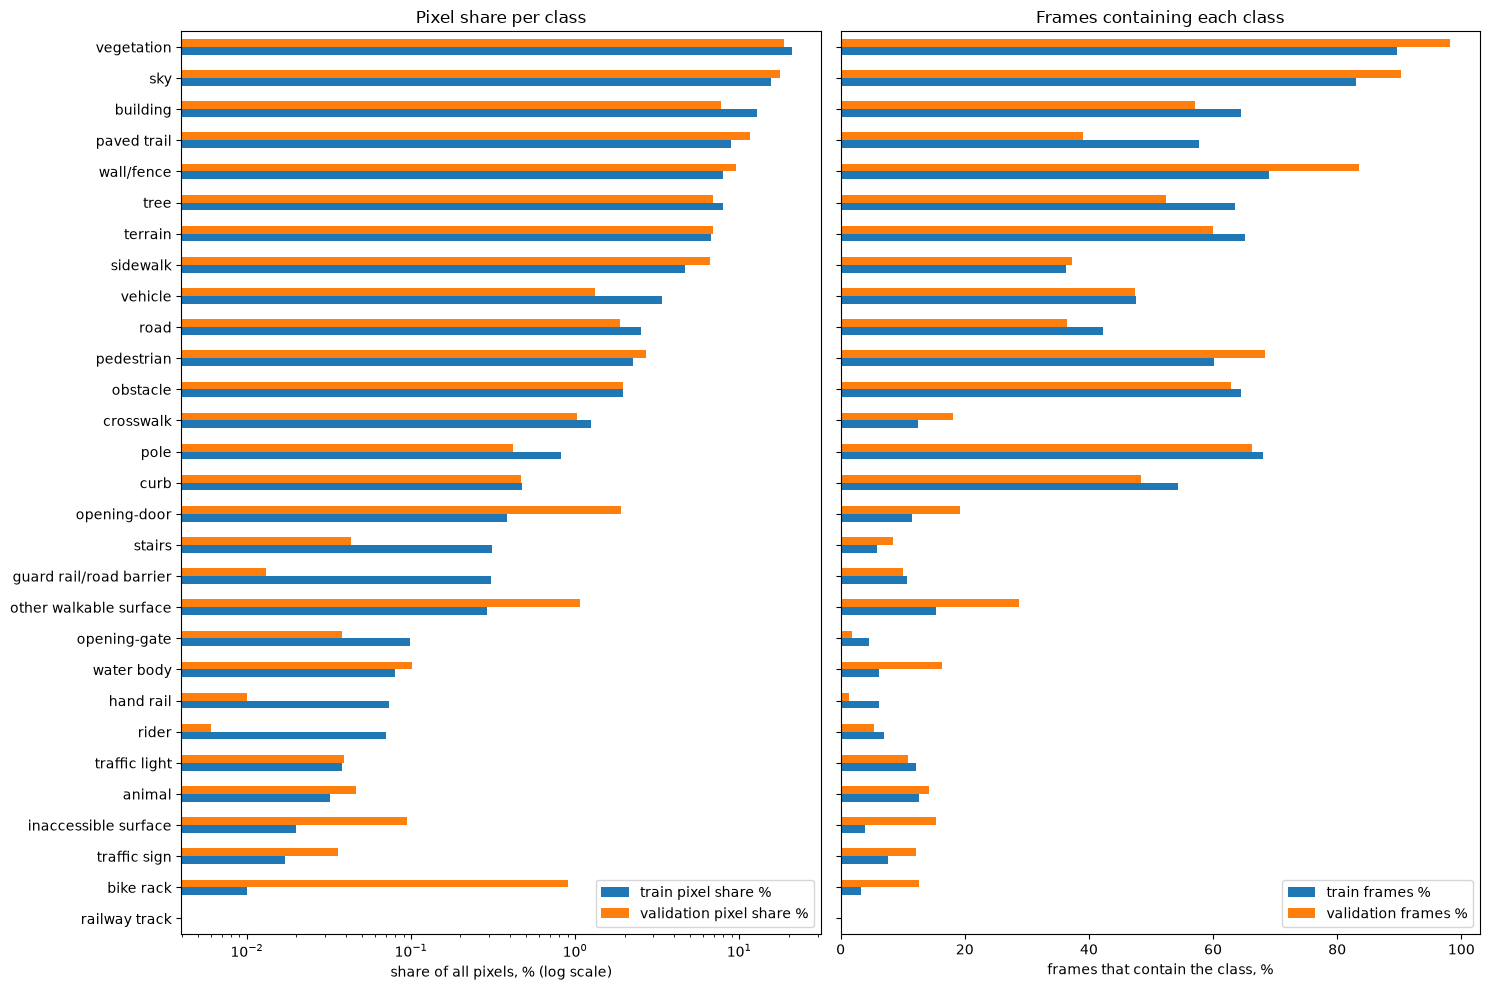

In [13]:
ordered = class_comparison.sort_values("train pixel share %")
figure, axes = plt.subplots(1, 2, figsize=(15, 10), sharey=True)
ordered[["train pixel share %", "validation pixel share %"]].plot(kind="barh", ax=axes[0], logx=True)
axes[0].set_xlabel("share of all pixels, % (log scale)")
axes[0].set_title("Pixel share per class")
ordered[["train frames %", "validation frames %"]].plot(kind="barh", ax=axes[1])
axes[1].set_xlabel("frames that contain the class, %")
axes[1].set_title("Frames containing each class")
plt.tight_layout()
plt.show()

## 9. Comparison: walk attributes (SANPO's descriptions)

Share of walks with each value. A walk can have several environment types and weather conditions.


environment types


,train %,validation %
open space,6.1,0.0
open terrain,6.1,0.0
park,37.9,42.9
road junction,19.7,14.3
rural,9.1,28.6
suburban,3.0,0.0
urban,62.1,57.1



weather


,train %,validation %
cloudy,6.1,14.3
rainy,18.2,14.3
sunny,81.8,85.7



motion blur (SANPO)


,train %,validation %
low,95.5,85.7
medium,4.5,14.3



human traffic


,train %,validation %
low,53.0,42.9
moderate,28.8,42.9
heavy,18.2,14.3


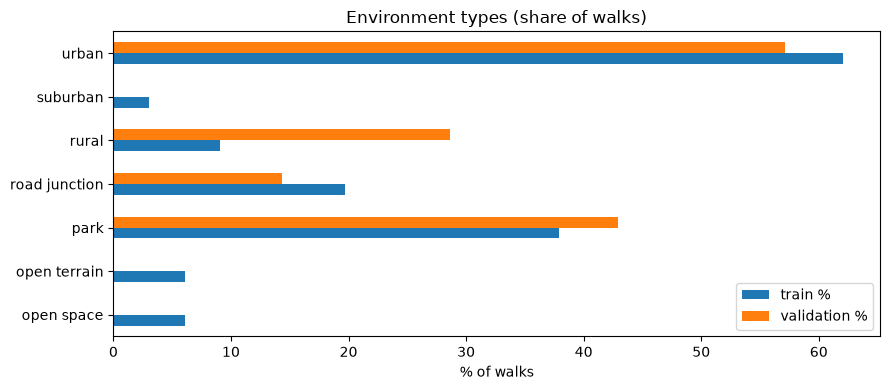

In [14]:
def attribute_shares(column):
    """Share of train and validation walks with each value of one attribute."""
    counts = {}
    for name, mask in [("train %", ~is_chosen), ("validation %", is_chosen)]:
        values = walk_attributes.loc[np.array(sessions)[mask], column]
        flat = []
        for value in values:
            flat.extend(value if isinstance(value, list) else [value])
        counts[name] = (100 * pd.Series(flat).value_counts() / mask.sum()).round(1)
    return pd.DataFrame(counts).fillna(0)


for column in ["environment types", "weather", "motion blur (SANPO)", "human traffic"]:
    print(f"\n{column}")
    display(attribute_shares(column))

attribute_shares("environment types").plot(kind="barh", figsize=(9, 4), title="Environment types (share of walks)")
plt.xlabel("% of walks")
plt.tight_layout()
plt.show()

## 10. Comparison: sharpness

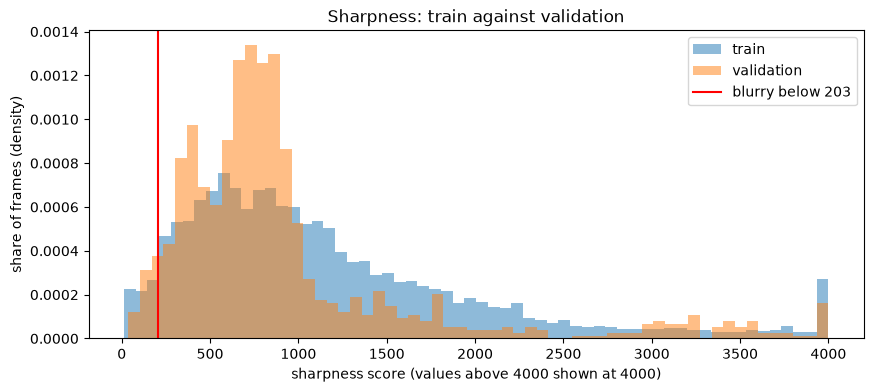

In [15]:
figure, axis = plt.subplots(figsize=(10, 4))
for name, mask in [("train", ~frames["session"].isin(chosen_walks)), ("validation", frames["session"].isin(chosen_walks))]:
    axis.hist(frames.loc[mask, "score"].clip(upper=4000), bins=60, density=True, alpha=0.5, label=name)
axis.axvline(blurry_score, color="red", label=f"blurry below {blurry_score:.0f}")
axis.set_xlabel("sharpness score (values above 4000 shown at 4000)")
axis.set_ylabel("share of frames (density)")
axis.set_title("Sharpness: train against validation")
axis.legend()
plt.show()

In [16]:
important = [
    "stairs",
    "curb",
    "hand rail",
    "guard rail/road barrier",
    "obstacle",
    "inaccessible surface",
]

print("Important class coverage in proposed Head validation:\n")

for name in important:
    idx = class_names.index(name)

    val_frames = int(walk_class_frames[is_chosen, idx].sum())
    train_frames = int(walk_class_frames[~is_chosen, idx].sum())

    print(
        f"{name:30s} "
        f"train={train_frames:5d}  "
        f"validation={val_frames:5d}"
    )

Important class coverage in proposed Head validation:

stairs                         train=  597  validation=   95
curb                           train= 5497  validation=  542
hand rail                      train=  621  validation=   15
guard rail/road barrier        train= 1080  validation=  113
obstacle                       train= 6509  validation=  705
inaccessible surface           train=  403  validation=  172


In [17]:
import json
import shutil
from datetime import datetime

expected_walks = sorted(final_walks)
final_mask = np.isin(sessions, expected_walks)

assert len(expected_walks) == 7
assert not broken_rules(final_mask)
assert set(expected_walks) <= head_eligible_train
assert int(walk_frames[final_mask].sum()) == 1120
assert int(walk_frames[~final_mask].sum()) == 10098

txt_path = RESULTS_DIR / "validation_walks.txt"
json_path = RESULTS_DIR / "validation_split.json"

saved_walks = (
    txt_path.read_text(encoding="utf-8").splitlines()
    if txt_path.exists() else []
)

saved_record = (
    json.loads(json_path.read_text(encoding="utf-8"))
    if json_path.exists() else {}
)

already_correct = (
    sorted(saved_walks) == expected_walks
    and saved_record.get("validation_frames") == 1120
    and saved_record.get("train_frames") == 10098
    and sorted(saved_record.get("validation_walks", [])) == expected_walks
)

if already_correct:
    print("Saved validation files already match the FINAL split.")
else:
    # Preserve existing files before updating.
    backup_dir = (
        RESULTS_DIR / "history" /
        datetime.now().strftime("%Y%m%d_%H%M%S")
    )
    backup_dir.mkdir(parents=True, exist_ok=True)

    for path in [txt_path, json_path]:
        if path.exists():
            shutil.copy2(path, backup_dir / path.name)

    final_record = {
        **record,
        "validation_walks": expected_walks,
        "validation_frames": 1120,
        "train_frames": 10098,
        "distances": {
            name: round(float(value), 5)
            for name, value in split_distances(final_mask).items()
        },
        "selection_note": (
            "Final 7-walk split includes road junction, "
            "moderate traffic, stairs, hand rail and traffic sign."
        ),
    }

    txt_path.write_text(
        "\n".join(expected_walks) + "\n",
        encoding="utf-8"
    )

    json_path.write_text(
        json.dumps(final_record, indent=2),
        encoding="utf-8"
    )

    print("Final validation files saved.")
    print("Previous versions backed up at:", backup_dir)

print("Validation walks:", len(expected_walks))
print("Validation frames:", int(walk_frames[final_mask].sum()))
print("Training frames:", int(walk_frames[~final_mask].sum()))

Saved validation files already match the FINAL split.
Validation walks: 7
Validation frames: 1120
Training frames: 10098
